# Model lineal de predicció demogràfica · Barcelona 1997–2026

+ **Durada estimada:** 2 hores
+ **Prerequisit:** exercici1.ipynb
+ **Eines:** Python 3 · pandas · numpy · matplotlib

---

## Pregunta de recerca

A partir de les dades de la gràfica *Distribució de la població per lloc de
naixement · 1997–2026*, construeix un model lineal **implementat des de zero,
amb gradient descendent**, que permeti respondre:

> **Si no canvien les tendències, quan superarà la població nascuda a la «Resta
> del món» la suma de la població nascuda a Barcelona, la Resta de Catalunya i
> la Resta d'Espanya?**

Recordatori dels grups del gràfic (`LLOC_NAIX`):

| Codi | Descripció |
|------|------------|
| 1 | Barcelona ciutat |
| 2 | Resta de Catalunya |
| 3 | Resta d'Espanya |
| 4 | Resta de la Unió Europea |
| 5 | Resta del món |
| 6 | No consta |

> **Nota:** Les cel·les marcades amb 🔧 contenen codi que has d'escriure o completar.
> Les marcades amb ✅ ja estan resoltes i serveixen de guia.

## Configuració inicial

In [1]:
# ✅
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

BASE          = "./data"
PATH_POBLACIO = os.path.join(BASE, "poblacio_lloc_naix")
PATH_DIMS     = os.path.join(BASE, "pad_dimensions.csv")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
})
print("\u2713 Configuraci\u00f3 carregada")

✓ Configuració carregada


In [2]:
# ✅ Càrrega de tota la sèrie temporal
def netejar_poblacio(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")
    df = df[df["LLOC_NAIX"].isin(range(1, 7))].copy()
    df["Any"] = pd.to_datetime(df["Data_Referencia"]).dt.year
    return df

fitxers  = sorted(glob.glob(os.path.join(PATH_POBLACIO, "*.csv")))
df_serie = pd.concat([netejar_poblacio(f) for f in fitxers], ignore_index=True)

serie_anual = (
    df_serie
    .groupby(["Any", "LLOC_NAIX"], as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Total"})
)
print(f"\u2713 {df_serie['Any'].nunique()} anys carregats "
      f"({df_serie['Any'].min()}\u2013{df_serie['Any'].max()})")

✓ 30 anys carregats (1997–2026)


---
## Part 1 — Dos grups de comparació

| Grup | Codis | Significat |
|------|-------|------------|
| **local** | 1, 2, 3 | Nascuts a Barcelona, Catalunya o Espanya |
| **exterior** | 4, 5 | Nascuts fora d'Espanya (UE, resta del món) |

Calcula per a cada any la població total de cada grup i la seva diferència
(`local − exterior`). Quan la diferència arribi a zero, els dos grups s'hauran
igualat.

In [3]:
# 🔧 Crea df_comparacio amb columnes: Any | local | exterior | diferencia
#
# 1) Etiquetem cada codi amb el seu grup. El codi 6 ("No consta") queda fora:
#    són molt poques persones (0–45 per any) i no sabem a quin grup pertanyen.
serie_grups = serie_anual[serie_anual["LLOC_NAIX"].isin([1, 2, 3, 4, 5])].copy()
serie_grups["Grup"] = np.where(serie_grups["LLOC_NAIX"].isin([1, 2, 3]), "local", "exterior")

# 2) + 3) Sumem per (Any, Grup) i passem els grups a columnes amb un pivot
df_comparacio = (
    serie_grups
    .groupby(["Any", "Grup"], as_index=False)["Total"].sum()
    .pivot(index="Any", columns="Grup", values="Total")
    .reset_index()[["Any", "local", "exterior"]]
)
df_comparacio.columns.name = None                 # treu el nom "Grup" de l'índex de columnes

# 4) Diferència: quan arribi a 0, els dos grups s'hauran igualat
df_comparacio["diferencia"] = df_comparacio["local"] - df_comparacio["exterior"]

assert len(df_comparacio) == 30, "Hi hauria d'haver una fila per any (1997–2026)"
print(df_comparacio.tail(5).to_string(index=False))

 Any     local  exterior  diferencia
2022 1158323.0  481155.0    677168.0
2023 1141369.0  518523.0    622846.0
2024 1129845.0  572382.0    557463.0
2025 1119537.0  611951.0    507586.0
2026 1102515.0  626889.0    475626.0


---
## Part 2 — Visualització de les tendències

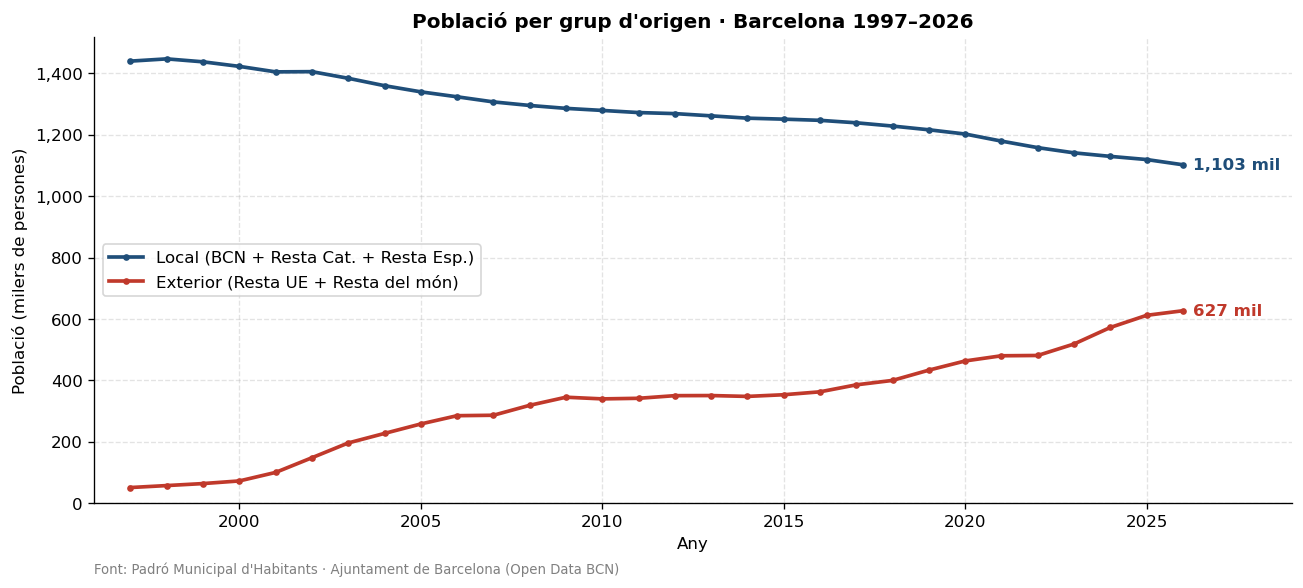

In [4]:
# 🔧 Gràfic de 2 línies: grup "local" i grup "exterior" 1997–2026
from matplotlib.ticker import FuncFormatter

COLORS = {"local": "#1f4e79", "exterior": "#c0392b"}
ETIQUETES = {"local": "Local (BCN + Resta Cat. + Resta Esp.)",
             "exterior": "Exterior (Resta UE + Resta del món)"}

fig, ax = plt.subplots(figsize=(11, 5))
for grup in ["local", "exterior"]:
    ax.plot(df_comparacio["Any"], df_comparacio[grup], color=COLORS[grup],
            linewidth=2.2, marker="o", markersize=3, label=ETIQUETES[grup])
    # Valor final (2026) a la dreta de cada línia
    valor_final = df_comparacio[grup].iloc[-1]
    ax.annotate(f"{valor_final / 1000:,.0f} mil", xy=(2026, valor_final),
                xytext=(6, 0), textcoords="offset points", va="center",
                color=COLORS[grup], fontweight="bold")

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1000:,.0f}"))
ax.set_xlim(1996, 2029)
ax.set_ylim(0, None)
ax.set_title("Població per grup d'origen · Barcelona 1997–2026", fontweight="bold")
ax.set_xlabel("Any")
ax.set_ylabel("Població (milers de persones)")
ax.legend(loc="center left")
ax.text(0, -0.15, "Font: Padró Municipal d'Habitants · Ajuntament de Barcelona (Open Data BCN)",
        transform=ax.transAxes, fontsize=8, color="gray")

plt.tight_layout()
plt.show()

---
## Part 3 — Regressió lineal i gradient descendent: conceptes

### El model

Volem ajustar una recta que descrigui com evoluciona la diferència
(`local − exterior`) al llarg del temps:

$$\hat{y} = m \cdot t + b$$

on $t$ és l'any, $\hat{y}$ és la diferència predita, $m$ és el
**pendent** i $b$ el **terme independent**.

### La funció de cost (MSE)

Per mesurar com de bé s'ajusta la recta usem l'**error quadràtic
mitjà** (*mean squared error*):

$$J(m, b) = \frac{1}{n} \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2
          = \frac{1}{n} \sum_{i=1}^{n} \left(y_i - (m \cdot t_i + b)\right)^2$$

L'objectiu és trobar els valors de $m$ i $b$ que **minimitzen** $J$.

### Gradient descendent

El **gradient descendent** actualitza $m$ i $b$ iterativament en la
direcció que redueix el cost:

$$m \leftarrow m - \alpha \cdot \frac{\partial J}{\partial m}
\qquad
b \leftarrow b - \alpha \cdot \frac{\partial J}{\partial b}$$

on $\alpha$ és la **taxa d'aprenentatge** (*learning rate*). 

Derivant $J$:

$$\frac{\partial J}{\partial m} = \frac{-2}{n}
  \sum_{i=1}^{n} t_i \cdot \left(y_i - (m \cdot t_i + b)\right)$$

$$\frac{\partial J}{\partial b} = \frac{-2}{n}
  \sum_{i=1}^{n} \left(y_i - (m \cdot t_i + b)\right)$$

### Per què normalitzar les dades?

Els anys $t$ van de 1997 a 2026 (valors grans) i les diferències $d$ de
població son de l'ordre de centenars de milers. Quan les escales
dels inputs i outputs son molt diferents, els gradients tenen
magnituds molt dispars i el descens és lent o inestable.

**Solució: estandardització** (*z-score*):

$$t_{\text{norm}} = \frac{t - \mu_t}{\sigma_t}
\qquad
d_{\text{norm}} = \frac{d - \mu_d}{\sigma_d}$$

Amb dades estandarditzades, una taxa d'aprenentatge $\alpha \in [0.01, 0.5]$ sol funcionar bé.

---
## Part 4 — Implementació del gradient descendent

Implementa el gradient descendent en quatre passos: normalització,
funció de cost, gradients i bucle d'entrenament.

In [5]:
# 🔧 4.1 · Estandarditza els anys i les diferències
#
# t_norm = (anys - anys.mean()) / anys.std()
# d_norm = (difs - difs.mean()) / difs.std()
#
# np.std() per defecte usa ddof=0 (desviació poblacional), així la std
# normalitzada surt exactament 1 i el cost inicial exactament 1.

anys = df_comparacio["Any"].values.astype(float)
difs = df_comparacio["diferencia"].values

t_mean, t_std = anys.mean(), anys.std()
d_mean, d_std = difs.mean(), difs.std()

t_norm = (anys - t_mean) / t_std
d_norm = (difs - d_mean) / d_std

print(f"t_norm: mean = {t_norm.mean():.6f}  std = {t_norm.std():.4f}")
print(f"d_norm: mean = {d_norm.mean():.6f}  std = {d_norm.std():.4f}")
# Hauria de sortir mean ≈ 0 i std ≈ 1 per a les dues variables

t_norm: mean = 0.000000  std = 1.0000
d_norm: mean = -0.000000  std = 1.0000


In [6]:
# 🔧 4.2 · Funció de cost: MSE
#
# J(m, b) = (1/n) * sum((y_i - (m*t_i + b))^2)

def cost_mse(m, b, t, y):
    """
    Calcula l'error quadràtic mitjà del model y_pred = m*t + b.

    Paràmetres:
        m, b : float  — pendent i terme independent actuals
        t    : array  — anys (normalitzats)
        y    : array  — diferències (normalitzades)
    Retorna:
        float — valor del MSE
    """
    y_pred = m * t + b                 # predicció per a tots els punts alhora (vectoritzat)
    return np.mean((y - y_pred) ** 2)  # mitjana dels errors al quadrat

# Comprova: amb m=0, b=0 i dades estandarditzades el cost hauria de ser ≈ 1.0
print(f"Cost inicial (m=0, b=0): {cost_mse(0, 0, t_norm, d_norm):.6f}")

Cost inicial (m=0, b=0): 1.000000


In [7]:
# 🔧 4.3 · Càlcul dels gradients
#
# dJ/dm = (-2/n) * sum( t_i * (y_i - (m*t_i + b)) )
# dJ/db = (-2/n) * sum(        y_i - (m*t_i + b)  )

def compute_gradients(m, b, t, y):
    """
    Calcula les derivades parcials del MSE respecte a m i b.

    Retorna:
        (dL_dm, dL_db) : tuple de floats
    """
    n = len(t)
    error = y - (m * t + b)                 # residus: valor real − predicció
    dL_dm = (-2 / n) * np.sum(t * error)
    dL_db = (-2 / n) * np.sum(error)
    return dL_dm, dL_db

# Comprova: el gradient ha de ser no-zero per a m=0, b=0
dm, db = compute_gradients(0, 0, t_norm, d_norm)
print(f"Gradient inicial: dJ/dm = {dm:.4f},  dJ/db = {db:.4f}")

Gradient inicial: dJ/dm = 1.9638,  dJ/db = 0.0000


In [8]:
# 🔧 4.4 · Bucle de gradient descendent
#
# Per a cada iteració:
#   1. Calcula el cost i guarda'l a history.
#   2. Calcula els gradients amb compute_gradients.
#   3. Actualitza: m ← m - lr * dL_dm
#                  b ← b - lr * dL_db
#
# Amb dades estandarditzades, lr = 0.1 convergeix ràpid i sense oscil·lar
# (amb lr ≥ 1 el cost divergeix). Amb 500 iteracions la corba ja és plana.

lr     = 0.1
n_iter = 500

m_norm, b_norm = 0.0, 0.0
history = []

for i in range(n_iter):
    history.append(cost_mse(m_norm, b_norm, t_norm, d_norm))         # 1. cost actual
    dL_dm, dL_db = compute_gradients(m_norm, b_norm, t_norm, d_norm)  # 2. gradients
    m_norm -= lr * dL_dm                                              # 3. pas en sentit
    b_norm -= lr * dL_db                                              #    contrari al gradient

print(f"Paràmetres finals (espai norm.): m = {m_norm:.4f}, b = {b_norm:.4f}")
print(f"Cost inicial: {history[0]:.6f}  |  Cost final: {history[-1]:.6f}")

Paràmetres finals (espai norm.): m = -0.9819, b = -0.0000
Cost inicial: 1.000000  |  Cost final: 0.035888


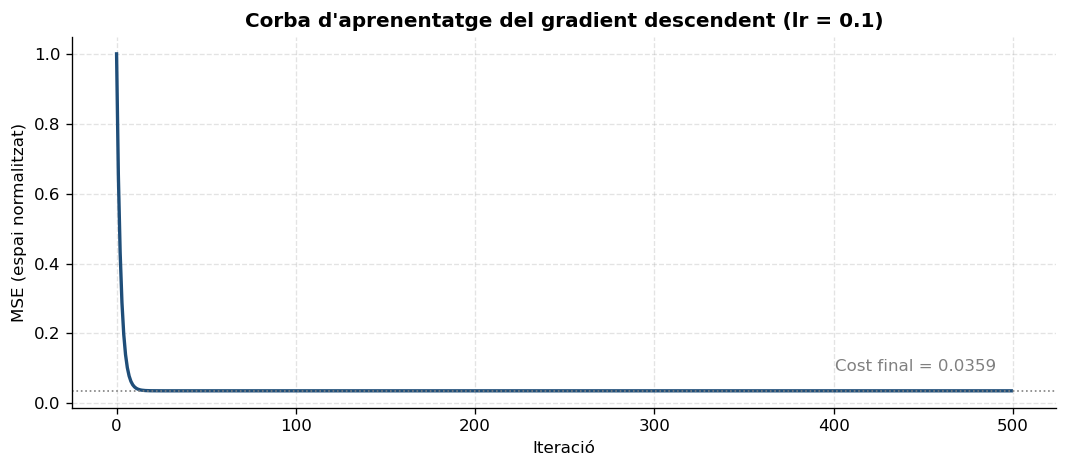

In [9]:
# 🔧 4.5 · Visualitza la corba d'aprenentatge (MSE vs. iteració)
#
# La corba ha de mostrar un descens ràpid al principi que s'aplanï.
# Si oscil·la o divergeix, redueix lr.

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(n_iter), history, color="#1f4e79", linewidth=2)
ax.axhline(history[-1], color="gray", linestyle=":", linewidth=1)
ax.annotate(f"Cost final = {history[-1]:.4f}", xy=(n_iter, history[-1]),
            xytext=(-10, 12), textcoords="offset points", ha="right", color="gray")
ax.set_title(f"Corba d'aprenentatge del gradient descendent (lr = {lr})", fontweight="bold")
ax.set_xlabel("Iteració")
ax.set_ylabel("MSE (espai normalitzat)")

plt.tight_layout()
plt.show()

In [10]:
# 🔧 4.6 · Converteix els paràmetres de l'espai normalitzat a l'original
#
# El model normalitzat és:  d_norm = m_norm * t_norm + b_norm
# Substituint t_norm i d_norm:
#
#   (d - d_mean)/d_std = m_norm * (t - t_mean)/t_std + b_norm
#
# Aïlla d per obtenir:
#
#   d = m_orig * t + b_orig
#
# on:
#   m_orig = m_norm * d_std / t_std
#   b_orig = d_std * b_norm + d_mean - m_orig * t_mean

m_orig = m_norm * d_std / t_std
b_orig = d_std * b_norm + d_mean - m_orig * t_mean

print(f"Model (escala original):")
print(f"  diferència = {m_orig:.0f} × any  +  {b_orig:.0f}")
print(f"  Pendent: {m_orig:.0f} persones/any")

Model (escala original):
  diferència = -29264 × any  +  59817930
  Pendent: -29264 persones/any


In [11]:
# ✅ Validació: compara el resultat de GD amb np.polyfit
coefs_ref = np.polyfit(anys, difs, 1)

print(f"{'M\u00e8tode':<20} {'m (pendent)':>14} {'b (intercept)':>15}")
print("-" * 52)
print(f"{'Gradient descendent':<20} {m_orig:>14.1f} {b_orig:>15.0f}")
print(f"{'np.polyfit (ref.)':<20} {coefs_ref[0]:>14.1f} {coefs_ref[1]:>15.0f}")
print()
err_m = abs(m_orig - coefs_ref[0]) / abs(coefs_ref[0]) * 100
err_b = abs(b_orig - coefs_ref[1]) / abs(coefs_ref[1]) * 100
print(f"Error relatiu:  m = {err_m:.2f}%   b = {err_b:.2f}%")
print("Si l'error < 1%, el gradient descendent ha convergit correctament.")

Mètode                  m (pendent)   b (intercept)
----------------------------------------------------
Gradient descendent        -29264.3        59817930
np.polyfit (ref.)          -29264.3        59817930

Error relatiu:  m = 0.00%   b = 0.00%
Si l'error < 1%, el gradient descendent ha convergit correctament.


---
## Part 5 — Punt de creuament

La diferència comença positiva i, si la tendència és lineal, arribarà a zero
en algun any futur. Aquell any és la resposta a la nostra pregunta.

Resol analíticament:

$$m_{\text{orig}} \cdot t^{*} + b_{\text{orig}} = 0
\quad \Longrightarrow \quad
t^{*} = -\frac{b_{\text{orig}}}{m_{\text{orig}}}$$

In [12]:
# 🔧 Calcula l'any de creuament usant m_orig i b_orig
# m·t* + b = 0  →  t* = −b / m   (m < 0: la diferència es redueix cada any)

any_creuament = -b_orig / m_orig

print(f"Any de creuament: {any_creuament:.2f}")
print(f"→ Cap a l'any {int(np.ceil(any_creuament))}, la 'Resta del món' superarà BCN+Cat+Esp")

Any de creuament: 2044.06
→ Cap a l'any 2045, la 'Resta del món' superarà BCN+Cat+Esp


---
## Part 6 — Visualització final amb projecció

Crea un gràfic que mostri:
- Els punts de la **diferència observada** (1997–2026).
- La **recta del model** extrapolada fins al punt de creuament (línia discontínua).
- La **línia zero** i el **punt de creuament** anotat.

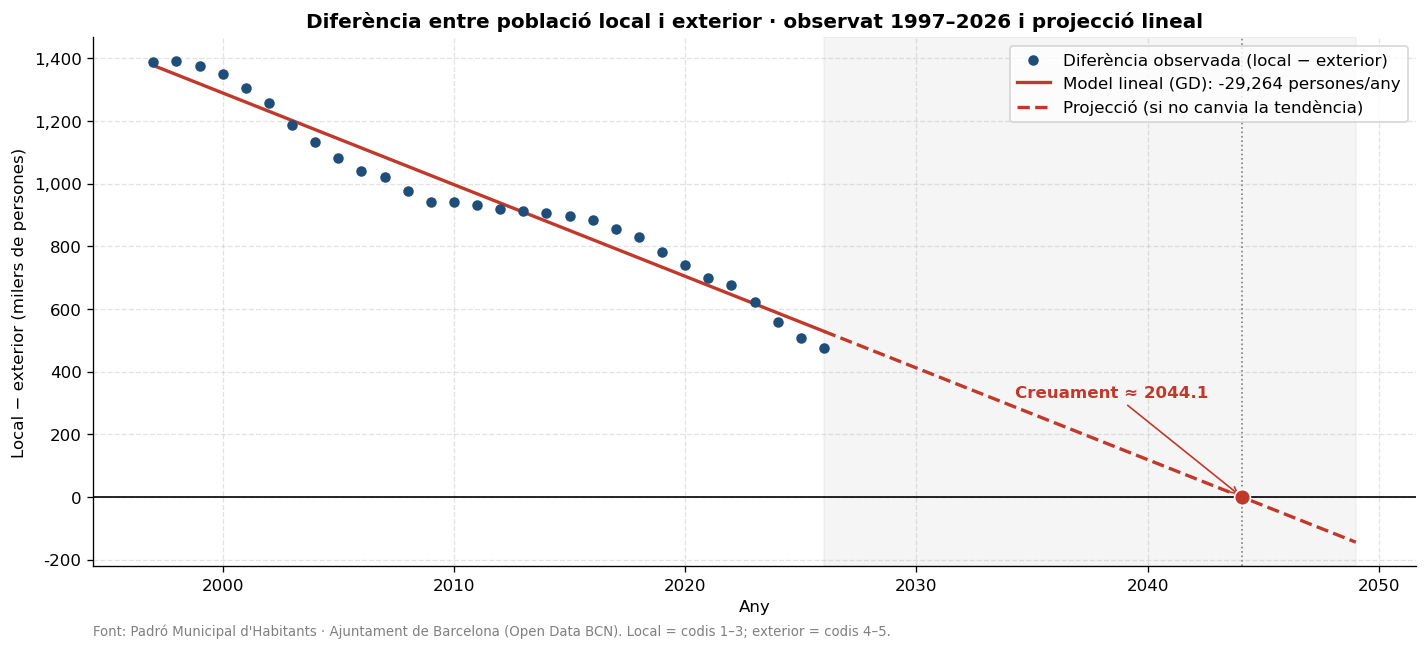

In [13]:
# 🔧 Gràfic de la diferència + model + projecció

model_orig = lambda t: m_orig * t + b_orig

anys_proj = np.arange(1997, int(any_creuament) + 6)

fig, ax = plt.subplots(figsize=(12, 5.5))
# Dades observades
ax.scatter(anys, difs, color="#1f4e79", s=28, zorder=3,
           label="Diferència observada (local − exterior)")
# Recta del model: contínua al període observat, discontínua a la projecció
anys_obs = anys_proj[anys_proj <= 2026]
anys_fut = anys_proj[anys_proj >= 2026]
ax.plot(anys_obs, model_orig(anys_obs), color="#c0392b", linewidth=2,
        label=f"Model lineal (GD): {m_orig:,.0f} persones/any")
ax.plot(anys_fut, model_orig(anys_fut), color="#c0392b", linewidth=2, linestyle="--",
        label="Projecció (si no canvia la tendència)")
# Línia zero i punt de creuament
ax.axhline(0, color="black", linewidth=1)
ax.axvline(any_creuament, color="gray", linestyle=":", linewidth=1)
ax.axvspan(2026, anys_proj[-1], color="gray", alpha=0.08)
ax.scatter([any_creuament], [0], color="#c0392b", s=90, zorder=4, edgecolor="white")
ax.annotate(f"Creuament ≈ {any_creuament:.1f}", xy=(any_creuament, 0),
            xytext=(-20, 60), textcoords="offset points", ha="right",
            fontweight="bold", color="#c0392b",
            arrowprops=dict(arrowstyle="->", color="#c0392b"))

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y / 1000:,.0f}"))
ax.set_title("Diferència entre població local i exterior · observat 1997–2026 i projecció lineal",
             fontweight="bold")
ax.set_xlabel("Any")
ax.set_ylabel("Local − exterior (milers de persones)")
ax.legend(loc="upper right")
ax.text(0, -0.13, "Font: Padró Municipal d'Habitants · Ajuntament de Barcelona (Open Data BCN). "
        "Local = codis 1–3; exterior = codis 4–5.",
        transform=ax.transAxes, fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("grafic_projeccio.png", bbox_inches="tight", dpi=150)
plt.show()

---
## Part 7 — Interpretació crítica

Respon les preguntes següents en les cel·les Markdown (3-5 frases per apartat).

**a) Quan superarà la «Resta del món» els grups locals? Quin és el grau de
confiança d'aquesta predicció?**

**Resposta:** Segons el model lineal ajustat a tota la sèrie (1997–2026), la diferència es redueix unes 29.000 persones/any i arriba a zero cap al **2044**: a partir d'aquell any la població nascuda fora d'Espanya superaria la suma de nascuts a Barcelona, a la resta de Catalunya i a la resta d'Espanya. La confiança és **baixa**: estem extrapolant 18 anys més enllà de les dades, i la predicció depèn del supòsit que la tendència sigui constant, cosa que la sèrie mateixa contradiu (vegeu l'apartat c). Si només fem servir l'última dècada (2016–2026), on el ritme és d'uns −42.000/any, el creuament s'avançaria a l'any **~2037**; és a dir, segons quin període triem la resposta canvia en gairebé una dècada. A més, el model no té en compte factors que no són a les dades (polítiques migratòries, preu de l'habitatge, crisis econòmiques, natalitat) i no dona cap interval d'incertesa, de manera que l'any 2044 s'ha de llegir com un ordre de magnitud ("cap a mitjans dels anys 2040, si res no canvia"), no com una previsió precisa.

**b) Quina influència té la tria de `lr` (learning rate) i `n_iter` sobre
el resultat? Qu passa si `lr` és massa gran? I massa petit?**

**Resposta:** `lr` i `n_iter` no canvien la recta *òptima* (la que minimitza el MSE, la mateixa que dona `np.polyfit`), sinó si l'algorisme hi arriba o no. Amb `lr = 0.1` i 500 iteracions el cost s'aplana ràpidament i l'error relatiu respecte a `np.polyfit` és pràcticament zero. Si `lr` és **massa gran** (amb dades estandarditzades, a partir de ≈ 1), cada pas "se salta" el mínim: el cost oscil·la i acaba divergint cap a infinit, i els paràmetres no tenen cap sentit. Si `lr` és **massa petit** (p. ex. 0.0001), cada pas és minúscul i amb 500 iteracions el model queda a mig camí: el pendent és menys negatiu del que toca i, per tant, l'any de creuament surt molt més tard (o fins i tot no surt). `n_iter` ha de ser prou gran perquè, amb el `lr` triat, la corba d'aprenentatge quedi plana; més iteracions a partir d'aquell punt només gasten temps.

**c) Un model lineal assumeix un ritme de canvi constant. Observes algun
període on la tendència va ser significativament diferent (crisi 2008,
pandèmia 2020)? Com afecta aixó a la fiabilitat de la predicció?**

**Resposta:** Sí, la sèrie té almenys tres trams ben diferents. Entre el **2000 i el 2008** (boom immigratori) la diferència cau ràpidament, unes 42.000 persones/any. Amb la **crisi del 2008** el ritme gairebé s'atura: entre el 2009 i el 2016 la diferència només es redueix uns 8.000/any, perquè arriba poca gent i alguns immigrants marxen. A partir del **2017** torna a accelerar, amb un petit alentiment durant la **pandèmia (2020–2022)** i un nou salt el 2023–2026. La recta única fa una "mitjana" d'aquests règims (−29.000/any), de manera que no descriu bé cap període concret: els residus no són aleatoris sinó que tenen forma d'ona (les dades queden per sobre de la recta el 1997–2002 i el 2013–2022, i per sota el 2004–2011 i el 2024–2026). Fixem-nos que els darrers punts ja estan per sota de la recta: el ritme actual és més ràpid que el que suposa el model. Això vol dir que la fiabilitat de la predicció és limitada: una nova crisi o un canvi de política migratòria podria aturar la convergència com el 2008, i una acceleració com la recent la faria arribar abans. Una millora seria ajustar el model només als darrers anys, provar models no lineals o, millor encara, presentar diversos escenaris en lloc d'un sol any.